# So sánh ba thời điểm A/B/C (RQ3)
Nguyễn Minh Triết — 3124411320.

So sánh LR, DT, RF, GB và SVM trên cùng 3.539 mẫu train, dùng Stratified 5-fold với seed 42.
A có 24 biến ban đầu, B thêm kết quả học kỳ 1, C thêm kết quả học kỳ 2.
Giữ cấu hình đã chọn trên C khi so sánh các mốc và fit lại toàn bộ pipeline trong từng fold.
LR và SVM có bước chuẩn hóa.

Cấu hình RF/GB/SVM lấy từ bảng tuning, LR/DT lấy từ `models/sv3_metadata.json`.
Đây là kết quả CV sau khi chọn cấu hình; 885 mẫu hold-out vẫn được giữ riêng cho đánh giá cuối.
Chạy và lưu notebook 04 trước khi chạy notebook 05. Thông tin môi trường và lượt chạy nằm ở cuối notebook.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/config.py").is_file() and (p / "src/data.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import config
from src.data import load_data, get_train_test
from src.evaluate import get_cv, compute_metrics, report, confusion
from src.preprocessing import build_pipeline, get_feature_names
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 20)
REPORTS = ROOT / "reports"
DATA_HASH = hashlib.sha256(config.DATA_FILE.read_bytes()).hexdigest()
rf_source = json.loads((REPORTS / "rf_summary.json").read_text(encoding="utf-8"))
assert DATA_HASH == rf_source["data_sha256"], "Dữ liệu khác lượt tuning RF được bàn giao"
gb_source = pd.read_csv(REPORTS / "gb_search_results.csv").sort_values("rank_test_score").iloc[0]
svm_source = pd.read_csv(REPORTS / "svm_search_results.csv").sort_values("rank_test_score").iloc[0]
PARAMS = {
    "RF": {k.removeprefix("clf__"): v for k, v in rf_source["best_params"].items()},
    "GB": {"n_estimators": int(gb_source["param_clf__n_estimators"]),
           "learning_rate": float(gb_source["param_clf__learning_rate"]),
           "max_depth": int(gb_source["param_clf__max_depth"]),
           "subsample": float(gb_source["param_clf__subsample"])},
    "SVM": {"C": float(svm_source["param_clf__C"]),
            "kernel": str(svm_source["param_clf__kernel"]),
            "gamma": float(svm_source["param_clf__gamma"]),
            "class_weight": str(svm_source["param_clf__class_weight"])},
}

# Nhận cấu hình LR/DT từ bàn giao trong repo; fit lại trong từng fold.
sv3_path = ROOT / "models/sv3_metadata.json"
sv3_metadata = json.loads(sv3_path.read_text(encoding="utf-8-sig"))
assert sv3_metadata["feature_set"] == "C"
assert sv3_metadata["seed"] == config.RANDOM_STATE and sv3_metadata["n_splits"] == config.N_SPLITS
SV3_HANDOFF = {
    "metadata_path": "models/sv3_metadata.json",
    "metadata_sha256": hashlib.sha256(sv3_path.read_bytes()).hexdigest(),
    "original_environment": sv3_metadata["libs"],
    "models": {name: sv3_metadata["models"][name] for name in ["lr", "dt"]},
}
PARAMS["LR"] = {k.removeprefix("clf__"): v for k, v in SV3_HANDOFF["models"]["lr"]["best_params"].items()}
PARAMS["LR"].update(solver="saga", max_iter=2000, tol=1e-3)
PARAMS["DT"] = {k.removeprefix("clf__"): v for k, v in SV3_HANDOFF["models"]["dt"]["best_params"].items()}
MODELS = ["LR", "DT", "RF", "GB", "SVM"]

def make_model(name, feature_set):
    estimator = {
        "LR": lambda: LogisticRegression(**PARAMS["LR"], random_state=config.RANDOM_STATE),
        "DT": lambda: DecisionTreeClassifier(**PARAMS["DT"], random_state=config.RANDOM_STATE),
        "RF": lambda: RandomForestClassifier(**PARAMS["RF"], random_state=config.RANDOM_STATE, n_jobs=1),
        "GB": lambda: GradientBoostingClassifier(**PARAMS["GB"], random_state=config.RANDOM_STATE),
        "SVM": lambda: SVC(**PARAMS["SVM"], random_state=config.RANDOM_STATE),
    }[name]()
    return build_pipeline(estimator, feature_set, scale=(name in ["LR", "SVM"]))

X, holdout, y, holdout_y = get_train_test("C")
HOLDOUT_IDS = set(holdout.index)
del holdout, holdout_y
assert len(X) == 3539 and len(HOLDOUT_IDS) == 885
assert not set(X.index) & HOLDOUT_IDS
folds = list(get_cv().split(X, y))
coverage = np.zeros(len(X), dtype=int)
for tr, va in folds:
    assert not set(tr) & set(va)
    coverage[va] += 1
assert np.all(coverage == 1)
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib"]}
PROVENANCE = {"python": platform.python_version(), "versions": VERSIONS,
              "data_sha256": DATA_HASH, "seed": config.RANDOM_STATE,
              "folds": config.N_SPLITS, "train_rows": len(X), "holdout_rows_reserved": len(HOLDOUT_IDS),
              "parameters": PARAMS, "sv3_handoff": SV3_HANDOFF,
              "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in [ROOT / "src/config.py", ROOT / "src/data.py", ROOT / "src/features.py",
                             ROOT / "src/preprocessing.py", ROOT / "src/evaluate.py",
                             REPORTS / "rf_summary.json", REPORTS / "gb_search_results.csv",
                             REPORTS / "svm_search_results.csv", sv3_path]}}
print(json.dumps(PROVENANCE, ensure_ascii=False, indent=2))

from datetime import datetime
from zoneinfo import ZoneInfo
import nbformat
ABC_STARTED = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).isoformat()
def code_hash(path):
    notebook = nbformat.read(path, as_version=4)
    code = "\n".join(c.source for c in notebook.cells if c.cell_type == "code")
    return hashlib.sha256(code.encode("utf-8")).hexdigest()
ABC_CODE_HASH = code_hash(ROOT / "notebooks/04_timepoint.ipynb")


{
  "python": "3.12.10",
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "joblib": "1.6.0",
    "matplotlib": "3.11.2"
  },
  "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036",
  "seed": 42,
  "folds": 5,
  "train_rows": 3539,
  "holdout_rows_reserved": 885,
  "parameters": {
    "RF": {
      "n_estimators": 100,
      "min_samples_split": 10,
      "min_samples_leaf": 2,
      "max_features": "sqrt",
      "max_depth": null,
      "class_weight": "balanced"
    },
    "GB": {
      "n_estimators": 200,
      "learning_rate": 0.05,
      "max_depth": 4,
      "subsample": 0.85
    },
    "SVM": {
      "C": 10.0,
      "kernel": "rbf",
      "gamma": 0.003,
      "class_weight": "balanced"
    },
    "LR": {
      "C": 0.3,
      "class_weight": "balanced",
      "penalty": "l2",
      "solver": "saga",
      "max_iter": 2000,
      "tol": 0.001
    },
    "DT": {
      "ccp_alpha": 0.

## 1. Kiểm tra tập biến và cách chia dữ liệu

Các đặc trưng mới được tạo trong pipeline từ thông tin có ở từng thời điểm.
A và B không dùng kết quả học kỳ 2. Nhóm giả định thông tin tài chính và học bổng
đã có tại mốc tương ứng; dữ liệu UCI không có lịch sử cập nhật để kiểm tra giả định này.


In [2]:
timepoint_rows = []
for fs in ["A", "B", "C"]:
    Xt, Xh, yt, yh = get_train_test(fs)
    assert Xt.index.equals(X.index) and yt.equals(y)
    assert set(Xh.index) == HOLDOUT_IDS
    assert list(Xt.columns) == config.FEATURE_SETS[fs]
    if fs == "A":
        assert not any("sem" in c for c in Xt.columns)
    if fs == "B":
        assert not any("2nd sem" in c for c in Xt.columns)
    timepoint_rows.append({"mốc": fs, "biến gốc": Xt.shape[1], "train": len(Xt), "holdout giữ riêng": len(Xh)})
display(pd.DataFrame(timepoint_rows))
del Xt, Xh, yt, yh

,mốc,biến gốc,train,holdout giữ riêng
0,A,24,3539,885
1,B,30,3539,885
2,C,36,3539,885


## 2. Chạy 5 mô hình ở ba thời điểm

Có 75 lượt fit: 5 mô hình × 3 mốc × 5 fold. Các độ đo được tính bằng
`src.evaluate.compute_metrics`. Kết quả từng fold được lưu để so sánh A/B/C.
Dự đoán OOF của RF-C được dùng cho phân tích lỗi ở issue #16.
RF-C được chọn làm tham chiếu theo phần RF đã bàn giao, chưa phải mô hình cuối của nhóm.


In [3]:
import time
rows, oof_parts = [], []
for fs in ["A", "B", "C"]:
    Xfs = X[config.FEATURE_SETS[fs]]
    for name in MODELS:
        start = time.perf_counter()
        for fold, (tr, va) in enumerate(folds, 1):
            model = make_model(name, fs)
            # Không nhận lượt fit LR chưa hội tụ là kết quả hoàn thành.
            import warnings
            from sklearn.exceptions import ConvergenceWarning
            with warnings.catch_warnings():
                warnings.filterwarnings("error", category=ConvergenceWarning)
                model.fit(Xfs.iloc[tr], y.iloc[tr])
            pred = model.predict(Xfs.iloc[va])
            metrics = compute_metrics(y.iloc[va], pred)
            rows.append({"model": name, "feature_set": fs, "fold": fold,
                         "n_train": len(tr), "n_validation": len(va),
                         "train_f1_macro": compute_metrics(y.iloc[tr], model.predict(Xfs.iloc[tr]))["f1_macro"],
                         **metrics, "data_sha256": DATA_HASH})
            if name == "RF" and fs == "C":
                part = pd.DataFrame({"row_id": Xfs.index[va], "fold": fold,
                                     "actual": y.iloc[va].to_numpy(), "predicted": pred})
                probs = model.predict_proba(Xfs.iloc[va])
                for i, label in enumerate(model.classes_):
                    part[f"prob_{label}"] = probs[:, i]
                oof_parts.append(part)
        print(f"{name}-{fs}: 5 fold hoàn tất ({time.perf_counter()-start:.1f}s)", flush=True)

results = pd.DataFrame(rows)
oof = pd.concat(oof_parts, ignore_index=True).sort_values("row_id").reset_index(drop=True)
assert len(results) == len(MODELS) * 3 * config.N_SPLITS and results.groupby(["model", "feature_set"]).size().eq(5).all()
assert not results.isna().any().any()
assert oof.row_id.is_unique and set(oof.row_id) == set(X.index)
assert not set(oof.row_id) & HOLDOUT_IDS
assert np.allclose(oof.filter(like="prob_").sum(axis=1), 1)
assert (oof.actual.to_numpy() == y.loc[oof.row_id].to_numpy()).all()
results.to_csv(REPORTS / "timepoint_cv.csv", index=False)
oof.to_csv(REPORTS / "rf_oof.csv", index=False)
print("Đã kiểm tra: mỗi dòng train có đúng một dự đoán OOF; không có dòng hold-out.")

C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\Admin\MLGroup\DoAn_MayHoc\Nhom01-student-dropout\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


LR-A: 5 fold hoàn tất (2.4s)


... (21 outputs left out)

RF-C: 5 fold hoàn tất (4.4s)


GB-C: 5 fold hoàn tất (62.7s)


SVM-C: 5 fold hoàn tất (7.6s)


Đã kiểm tra: mỗi dòng train có đúng một dự đoán OOF; không có dòng hold-out.


## 3. So sánh kết quả A/B/C

Bảng trình bày trung bình và độ lệch chuẩn qua 5 fold, dùng `ddof=0` theo hàm chung.
Độ lệch chuẩn cho biết kết quả thay đổi giữa các fold, không phải khoảng tin cậy độc lập.


f1_macro_mean  f1_macro_std  balanced_accuracy_mean  \
model feature_set                                                        
DT    A                   0.4616        0.0180                  0.4919   
      B                   0.6254        0.0139                  0.6183   
      C                   0.6823        0.0139                  0.6747   
GB    A                   0.5611        0.0117                  0.5583   
      B                   0.6760        0.0217                  0.6678   
      C                   0.7139        0.0119                  0.7053   
LR    A                   0.5751        0.0208                  0.5862   
      B                   0.6810        0.0207                  0.6883   
      C                   0.7170        0.0191                  0.7246   
RF    A                   0.5896        0.0183                  0.5951   
      B                   0.6978        0.0255                  0.6993   
      C                   0.7256        0.0143                  0.7311   
SVM   A                   0.5690        0.0200                  0.5847   
      B                   0.6887        0.0193                  0.6982   
      C                   0.7213        0.0113                  0.7294   

                   balanced_accuracy_std  accuracy_mean  accuracy_std  \
model feature_set                                                       
DT    A                           0.0112         0.6183        0.0071   
      B                           0.0121         0.7256        0.0126   
      C                           0.0184         0.7482        0.0097   
GB    A                           0.0127         0.6635        0.0124   
      B                           0.0191         0.7553        0.0201   
      C                           0.0129         0.7821        0.0055   
LR    A                           0.0200         0.6086        0.0232   
      B                           0.0209         0.7219        0.0201   
      C                           0.0198         0.7578        0.0162   
RF    A                           0.0195         0.6324        0.0131   
      B                           0.0241         0.7437        0.0223   
      C                           0.0158         0.7666        0.0120   
SVM   A                           0.0195         0.5965        0.0204   
      B                           0.0204         0.7273        0.0174   
      C                           0.0114         0.7601        0.0104   

                   recall_Dropout_mean  recall_Dropout_std  f1_Enrolled_mean  \
model feature_set                                                              
DT    A                         0.6006              0.0390            0.0646   
      B                         0.6710              0.0206            0.3164   
      C                         0.6587              0.0135            0.4533   
GB    A                         0.6085              0.0462            0.2803   
      B                         0.7537              0.0304            0.4138   
      C                         0.7827              0.0244            0.4823   
LR    A                         0.5883              0.0625            0.3996   
      B                         0.7036              0.0318            0.4856   
      C                         0.7361              0.0228            0.5305   
RF    A                         0.6376              0.0322            0.4066   
      B                         0.7273              0.0371            0.5030   
      C                         0.7308              0.0205            0.5439   
SVM   A                         0.5364              0.0629            0.4037   
      B                         0.6719              0.0329            0.5090   
      C                         0.7273              0.0227            0.5398   

                   f1_Enrolled_std  train_f1_macro_mean  train_f1_macro_std  
model feature_set                                                            
D

,model,thay đổi,Δ Macro-F1 trung bình,SD Δ theo fold,số fold tăng
0,LR,A → B,0.1058,0.0137,5
1,LR,B → C,0.0361,0.0077,5
2,DT,A → B,0.1638,0.0263,5
3,DT,B → C,0.0569,0.0182,5
4,RF,A → B,0.1082,0.0196,5
5,RF,B → C,0.0278,0.0270,4
6,GB,A → B,0.1148,0.0173,5
7,GB,B → C,0.0379,0.0313,4
8,SVM,A → B,0.1196,0.0192,5
9,SVM,B → C,0.0326,0.0105,5


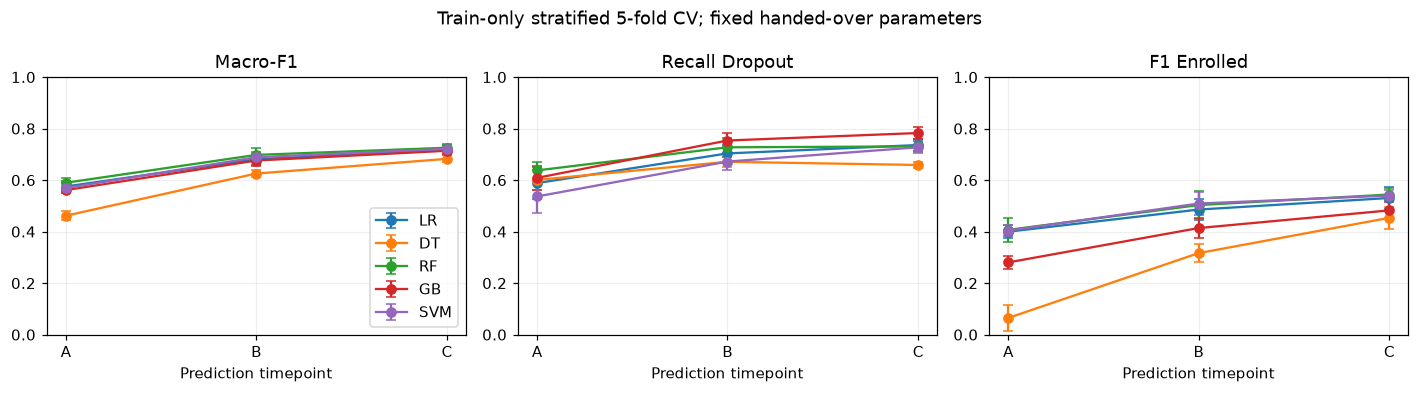

In [4]:
METRICS = ["f1_macro", "balanced_accuracy", "accuracy", "recall_Dropout", "f1_Enrolled", "train_f1_macro"]
summary = results.groupby(["model", "feature_set"])[METRICS].agg(["mean", lambda s: s.std(ddof=0)])
summary.columns = [f"{m}_{'std' if agg == '<lambda_0>' else agg}" for m, agg in summary.columns]
display(summary.round(4))
deltas = []
for name in MODELS:
    wide = results.loc[results.model.eq(name)].pivot(index="fold", columns="feature_set", values="f1_macro")
    for a, b in [("A", "B"), ("B", "C")]:
        delta = wide[b] - wide[a]
        deltas.append({"model": name, "thay đổi": f"{a} → {b}",
                       "Δ Macro-F1 trung bình": delta.mean(), "SD Δ theo fold": delta.std(ddof=0),
                       "số fold tăng": int((delta > 0).sum())})
display(pd.DataFrame(deltas).round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric, title in zip(axes, ["f1_macro", "recall_Dropout", "f1_Enrolled"],
                           ["Macro-F1", "Recall Dropout", "F1 Enrolled"]):
    for name in MODELS:
        values = summary.loc[name].reindex(["A", "B", "C"])
        ax.errorbar(["A", "B", "C"], values[f"{metric}_mean"],
                    yerr=values[f"{metric}_std"], marker="o", capsize=3, label=name)
    ax.set(title=title, xlabel="Prediction timepoint", ylim=(0, 1))
    ax.grid(alpha=.2)
axes[0].legend()
fig.suptitle("Train-only stratified 5-fold CV; fixed handed-over parameters")
fig.tight_layout()
plt.show()

In [5]:
lines = []
for name in MODELS:
    values = summary.loc[name]
    a, b, c = [values.loc[fs, "f1_macro_mean"] for fs in ["A", "B", "C"]]
    lines.append(f"- **{name}**: Macro-F1 A/B/C = {a:.4f}/{b:.4f}/{c:.4f}; "
                 f"B−A = {b-a:+.4f}, C−B = {c-b:+.4f}.")
display(Markdown("### Nhận xét từ lượt chạy\n" + "\n".join(lines) +
    "\n\nDùng mốc A/B để bàn về cảnh báo sớm, đồng thời báo mức đánh đổi chất lượng với C. "
    "Kết quả có điều kiện theo các cấu hình đã chọn trên C; không kết luận A/B đã được tối ưu. "
    "Khác biệt nhỏ cần xem độ lệch chuẩn và từng fold, không tự suy ra ý nghĩa thống kê. "
    "Hold-out chưa được chấm điểm."))

### Nhận xét từ lượt chạy
- **LR**: Macro-F1 A/B/C = 0.5751/0.6810/0.7170; B−A = +0.1058, C−B = +0.0361.
- **DT**: Macro-F1 A/B/C = 0.4616/0.6254/0.6823; B−A = +0.1638, C−B = +0.0569.
- **RF**: Macro-F1 A/B/C = 0.5896/0.6978/0.7256; B−A = +0.1082, C−B = +0.0278.
- **GB**: Macro-F1 A/B/C = 0.5611/0.6760/0.7139; B−A = +0.1148, C−B = +0.0379.
- **SVM**: Macro-F1 A/B/C = 0.5690/0.6887/0.7213; B−A = +0.1196, C−B = +0.0326.

Dùng mốc A/B để bàn về cảnh báo sớm, đồng thời báo mức đánh đổi chất lượng với C. Kết quả có điều kiện theo các cấu hình đã chọn trên C; không kết luận A/B đã được tối ưu. Khác biệt nhỏ cần xem độ lệch chuẩn và từng fold, không tự suy ra ý nghĩa thống kê. Hold-out chưa được chấm điểm.

## Thông tin lượt chạy để đối chiếu với notebook 05

Phần dưới ghi thời gian chạy, hash code và hash các file CSV.
Notebook 05 dùng thông tin này để kiểm tra kết quả có khớp hay không.
Sau khi chạy toàn bộ notebook 04, cần lưu lại rồi mới chạy 05.


In [6]:
abc_handoff = {
    "started_at": ABC_STARTED,
    "finished_at": datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).isoformat(),
    "data_sha256": DATA_HASH,
    "notebook_code_sha256": ABC_CODE_HASH,
    "provenance": PROVENANCE,
    "csv_sha256": {name: hashlib.sha256((REPORTS / name).read_bytes()).hexdigest()
                   for name in ["timepoint_cv.csv", "rf_oof.csv"]},
    "status": "passed",
}
print("SV5_ABC_HANDOFF=" + json.dumps(abc_handoff, ensure_ascii=False))


SV5_ABC_HANDOFF={"started_at": "2026-11-25T15:17:53.431084+07:00", "finished_at": "2026-11-25T15:21:33.678749+07:00", "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036", "notebook_code_sha256": "61d1d2e480ba4228c55adeca449baa2f1622ab4c982c1d3a4ba8c86be2028520", "provenance": {"python": "3.12.10", "versions": {"numpy": "2.5.4", "pandas": "3.1.1", "scipy": "1.18.1", "scikit-learn": "1.9.1", "joblib": "1.6.0", "matplotlib": "3.11.2"}, "data_sha256": "edc197d1381f25414a3757ab9bbae5f1f6d21aa6a964dbe98a148c15f3d63036", "seed": 42, "folds": 5, "train_rows": 3539, "holdout_rows_reserved": 885, "parameters": {"RF": {"n_estimators": 100, "min_samples_split": 10, "min_samples_leaf": 2, "max_features": "sqrt", "max_depth": null, "class_weight": "balanced"}, "GB": {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 4, "subsample": 0.85}, "SVM": {"C": 10.0, "kernel": "rbf", "gamma": 0.003, "class_weight": "balanced"}, "LR": {"C": 0.3, "class_weight": "balanced", 